# 05 - Controlled Experiments & Statistical Hypothesis Testing
**Project:** Robustness of Roman Urdu Sentiment Classification to Orthographic Spelling Variation  
**Course:** Data Science Tools & Techniques (DS T&T)  
**Author:** Danyal Ahmed Malik (26i-8030)

---
### Pipeline Overview & Objectives
1. **Experiment A (Zero-Shot Degradation & Factorial ANOVA):**
   - Evaluate all models across canonical conditions (`Clean`, `Mild`, `Moderate`, `Severe`).
   - Run $3 \times 3$ factorial evaluation grid (Substitution Rate $\times$ Edit Distance).
   - Compute paired bootstrap confidence intervals ($B=1,000$) and McNemar's statistical significance tests.
2. **Experiment B (Data Augmentation Resilience):**
   - Test whether training on synthetic authentic variant perturbations mitigates degradation without harming clean accuracy.
3. **Experiment C (Lexicon Normalization & Recovery Ablation):**
   - Evaluate four inference conditions: Condition A (Raw Perturbed), Condition B (Generic Preprocessing), Condition C (Lexicon Normalization), Condition D (Generic Preprocessing + Lexicon Normalization).
   - Quantify recovery predictability across variant density quartiles.
4. **Stage 4 (External Generalization):**
   - Evaluate cross-domain zero-shot transfer on RUECD (26,824 e-commerce reviews) and quantify domain overlap.


In [1]:
import os
import sys
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)


### 1. Experiment A: Canonical Degradation Results
Inspect canonical accuracy and Macro-F1 across Clean, Mild, Moderate, and Severe conditions.


In [2]:
exp_a_path = os.path.join(PROJECT_ROOT, "results", "tables", "experiment_A_canonical_results.csv")
exp_a_df = pd.read_csv(exp_a_path)
display(exp_a_df)

exp_a_sig = os.path.join(PROJECT_ROOT, "results", "tables", "experiment_A_significance.json")
with open(exp_a_sig, "r", encoding="utf-8") as f:
    sig_data = json.load(f)
print("Statistical Significance (McNemar & Bootstrap p-values):")
print(json.dumps(sig_data, indent=2))


Statistical Significance (McNemar & Bootstrap p-values):
{
  "xlmr_full_vs_lora_clean": {
    "f1_a": 0.48380444533840816,
    "f1_b": 0.5293876585106958,
    "delta": -0.04558321317228764,
    "ci_95_lower": -0.060568954848686844,
    "ci_95_upper": -0.03019762401254731,
    "p_value": 0.0,
    "significant_p05": true,
    "significant_p01": true
  },
  "xlmr_full_vs_lora_severe": {
    "f1_a": 0.44987963603388137,
    "f1_b": 0.5045903949985386,
    "delta": -0.05471075896465727,
    "ci_95_lower": -0.07067937335512986,
    "ci_95_upper": -0.03711732100084016,
    "p_value": 0.0,
    "significant_p05": true,
    "significant_p01": true
  },
  "mcnemar_xlmr_full_vs_lora_severe": {
    "chi2": 29.913834951456312,
    "p_value": 4.516783989065563e-08,
    "n01": 491,
    "n10": 333,
    "significant": true
  },
  "xlmr_full_clean_vs_severe": {
    "f1_a": 0.48380444533840816,
    "f1_b": 0.44987963603388137,
    "delta": 0.03392480930452679,
    "ci_95_lower": 0.02104899310294024,
    "

,model,condition,accuracy,macro_f1,macro_precision,macro_recall,weighted_f1,delta_macro_f1,rel_drop_macro_f1_pct,delta_accuracy,rel_drop_accuracy_pct
0,TF-IDF + LR,clean,0.544473,0.550812,0.544874,0.561026,0.541704,0.000000,0.000000,0.000000,0.000000
1,mBERT (Full),clean,0.579142,0.598060,0.601166,0.599478,0.577101,0.000000,0.000000,0.000000,0.000000
2,XLM-RoBERTa (Full),clean,0.485649,0.483804,0.521536,0.479353,0.481137,0.000000,0.000000,0.000000,0.000000
3,XLM-RoBERTa (LoRA),clean,0.522023,0.529388,0.535061,0.534680,0.517364,0.000000,0.000000,0.000000,0.000000
4,TF-IDF + LR,mild,0.508667,0.513548,0.508688,0.521786,0.506036,0.037264,6.765331,0.035806,6.576200
5,mBERT (Full),mild,0.563228,0.581829,0.589290,0.580221,0.561271,0.016231,2.713946,0.015914,2.747792
6,XLM-RoBERTa (Full),mild,0.474282,0.475070,0.512282,0.469521,0.470612,0.008735,1.805439,0.011367,2.340550
7,XLM-RoBERTa (LoRA),mild,0.512646,0.519706,0.529598,0.523359,0.507218,0.009682,1.828835,0.009378,1.796407
8,TF-IDF + LR,moderate,0.490764,0.492427,0.488273,0.501222,0.486859,0.058385,10.599779,0.053708,9.864301
9,mBERT (Full),moderate,0.550725,0.570548,0.581050,0.566043,0.549589,0.027512,4.600188,0.028417,4.906771


### 2. Experiment A Visualizations: Degradation Curves & Factorial Heatmap


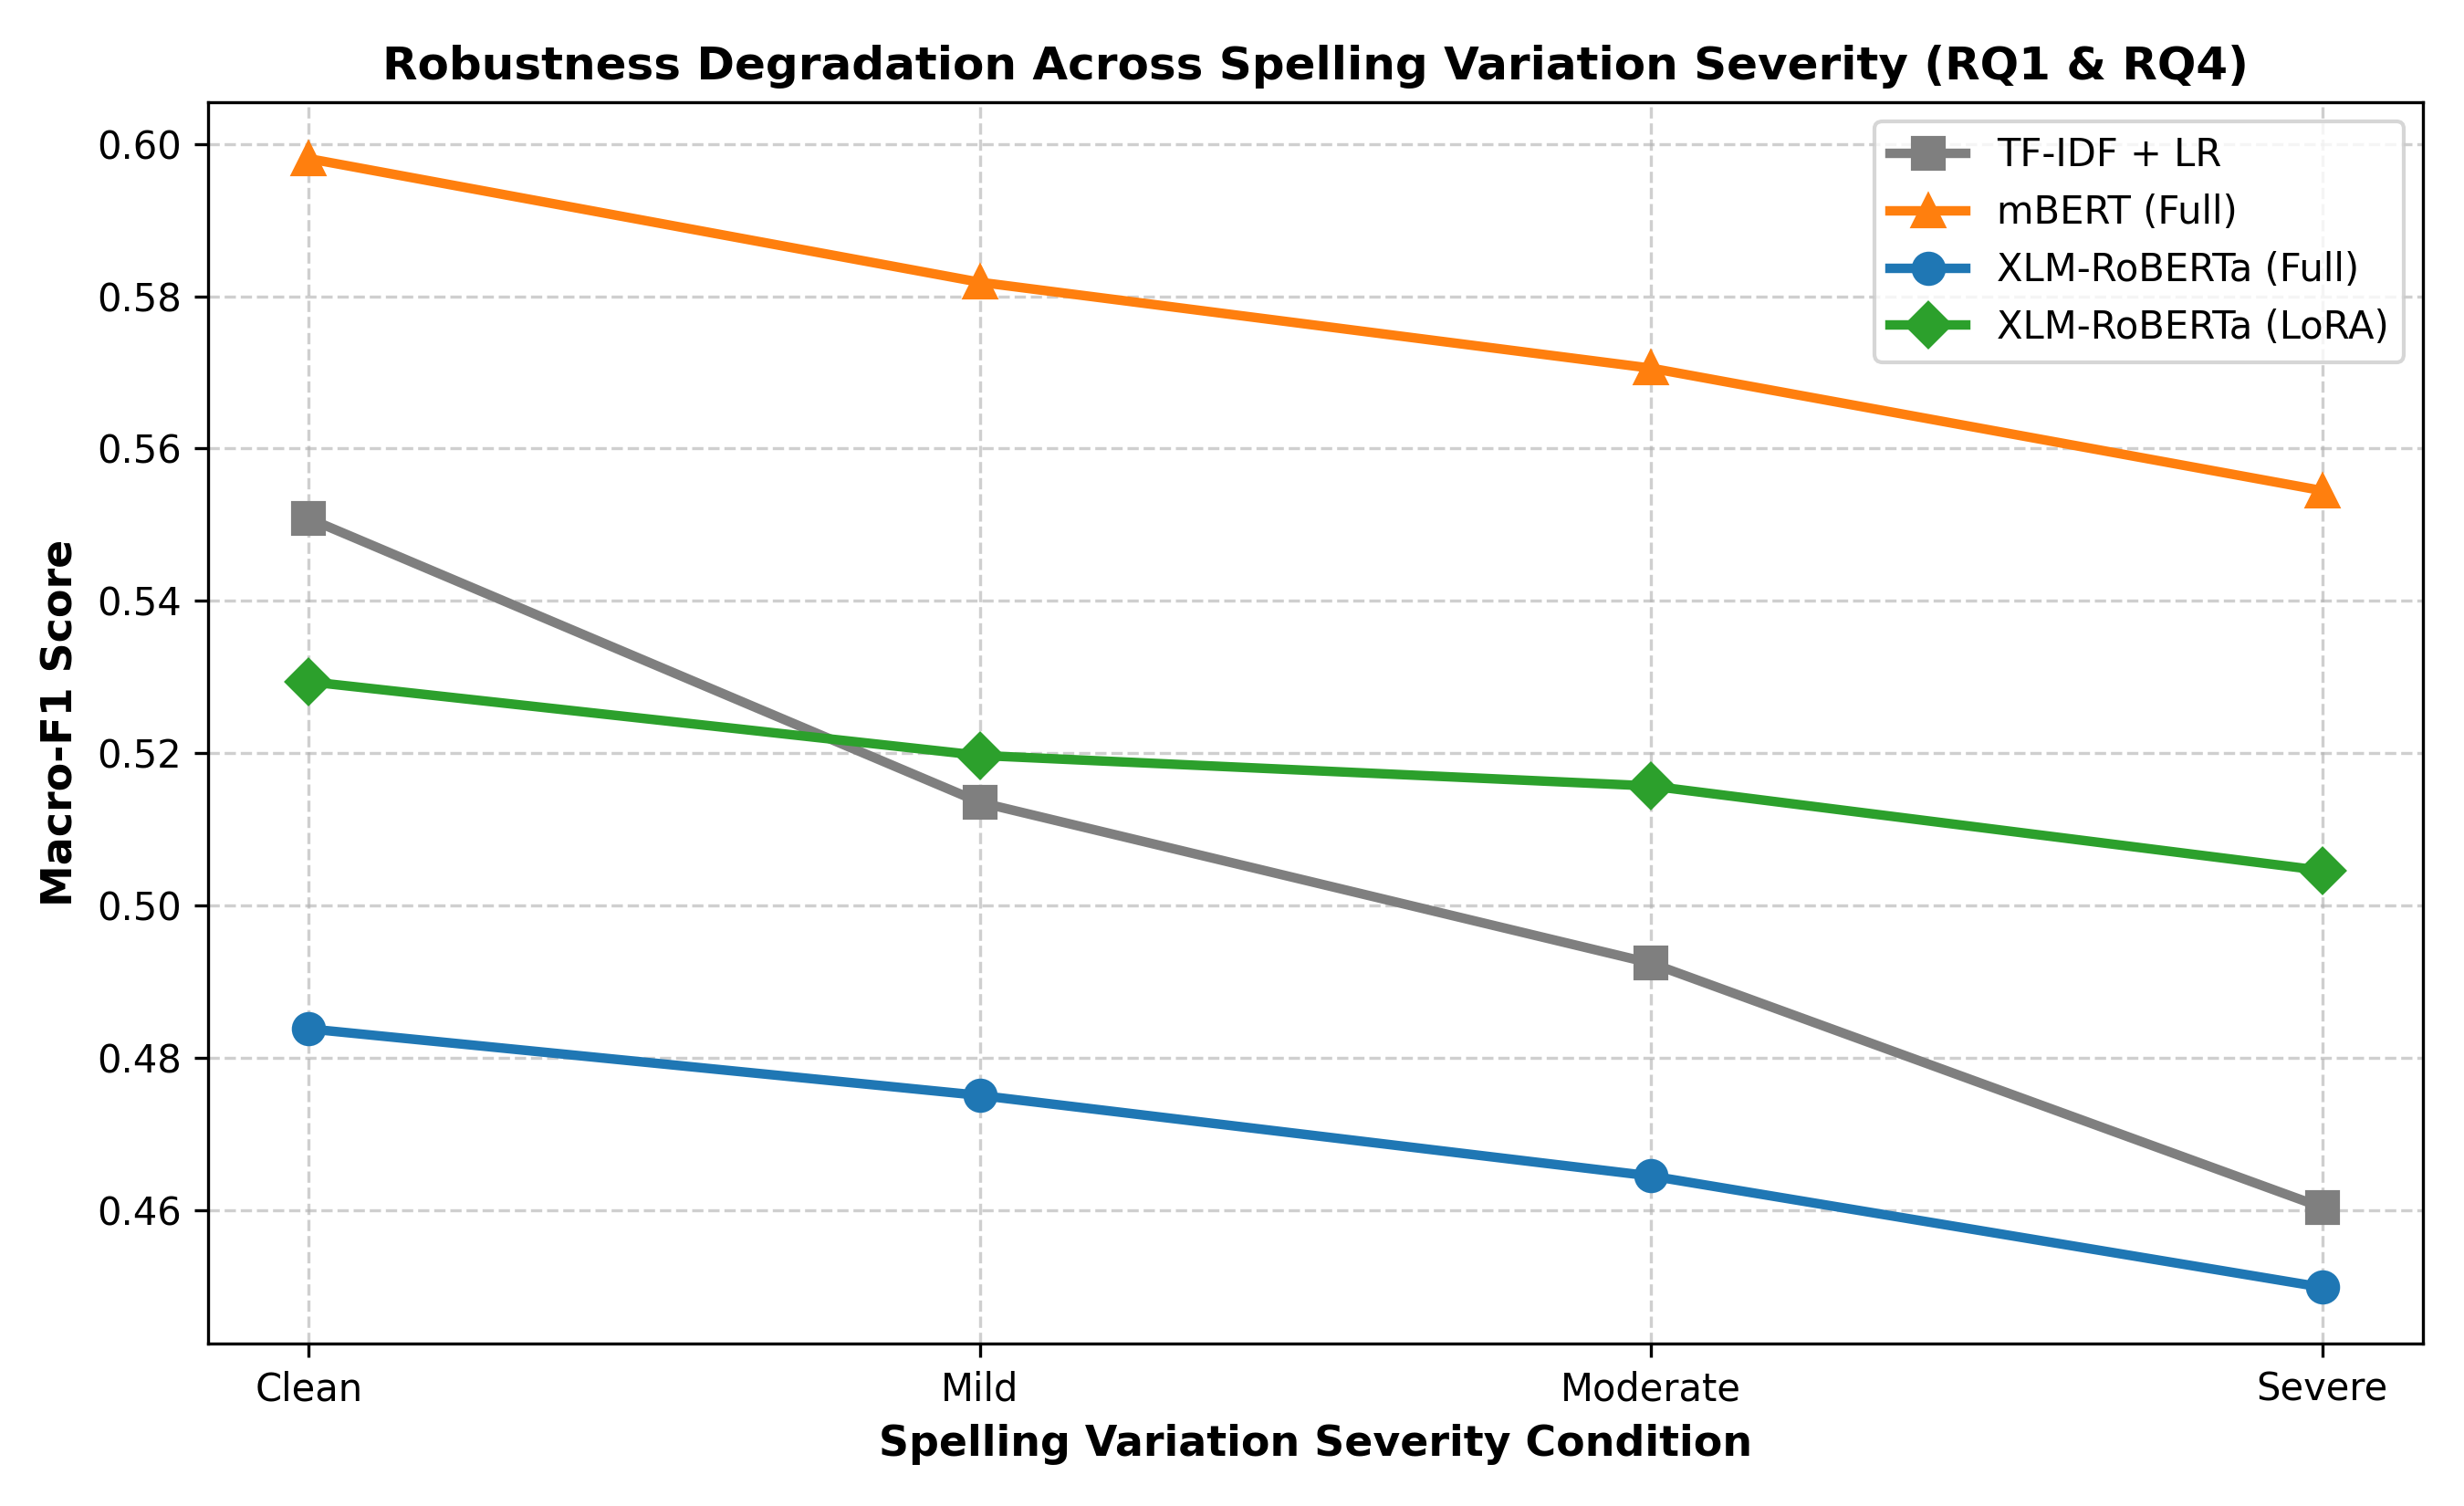

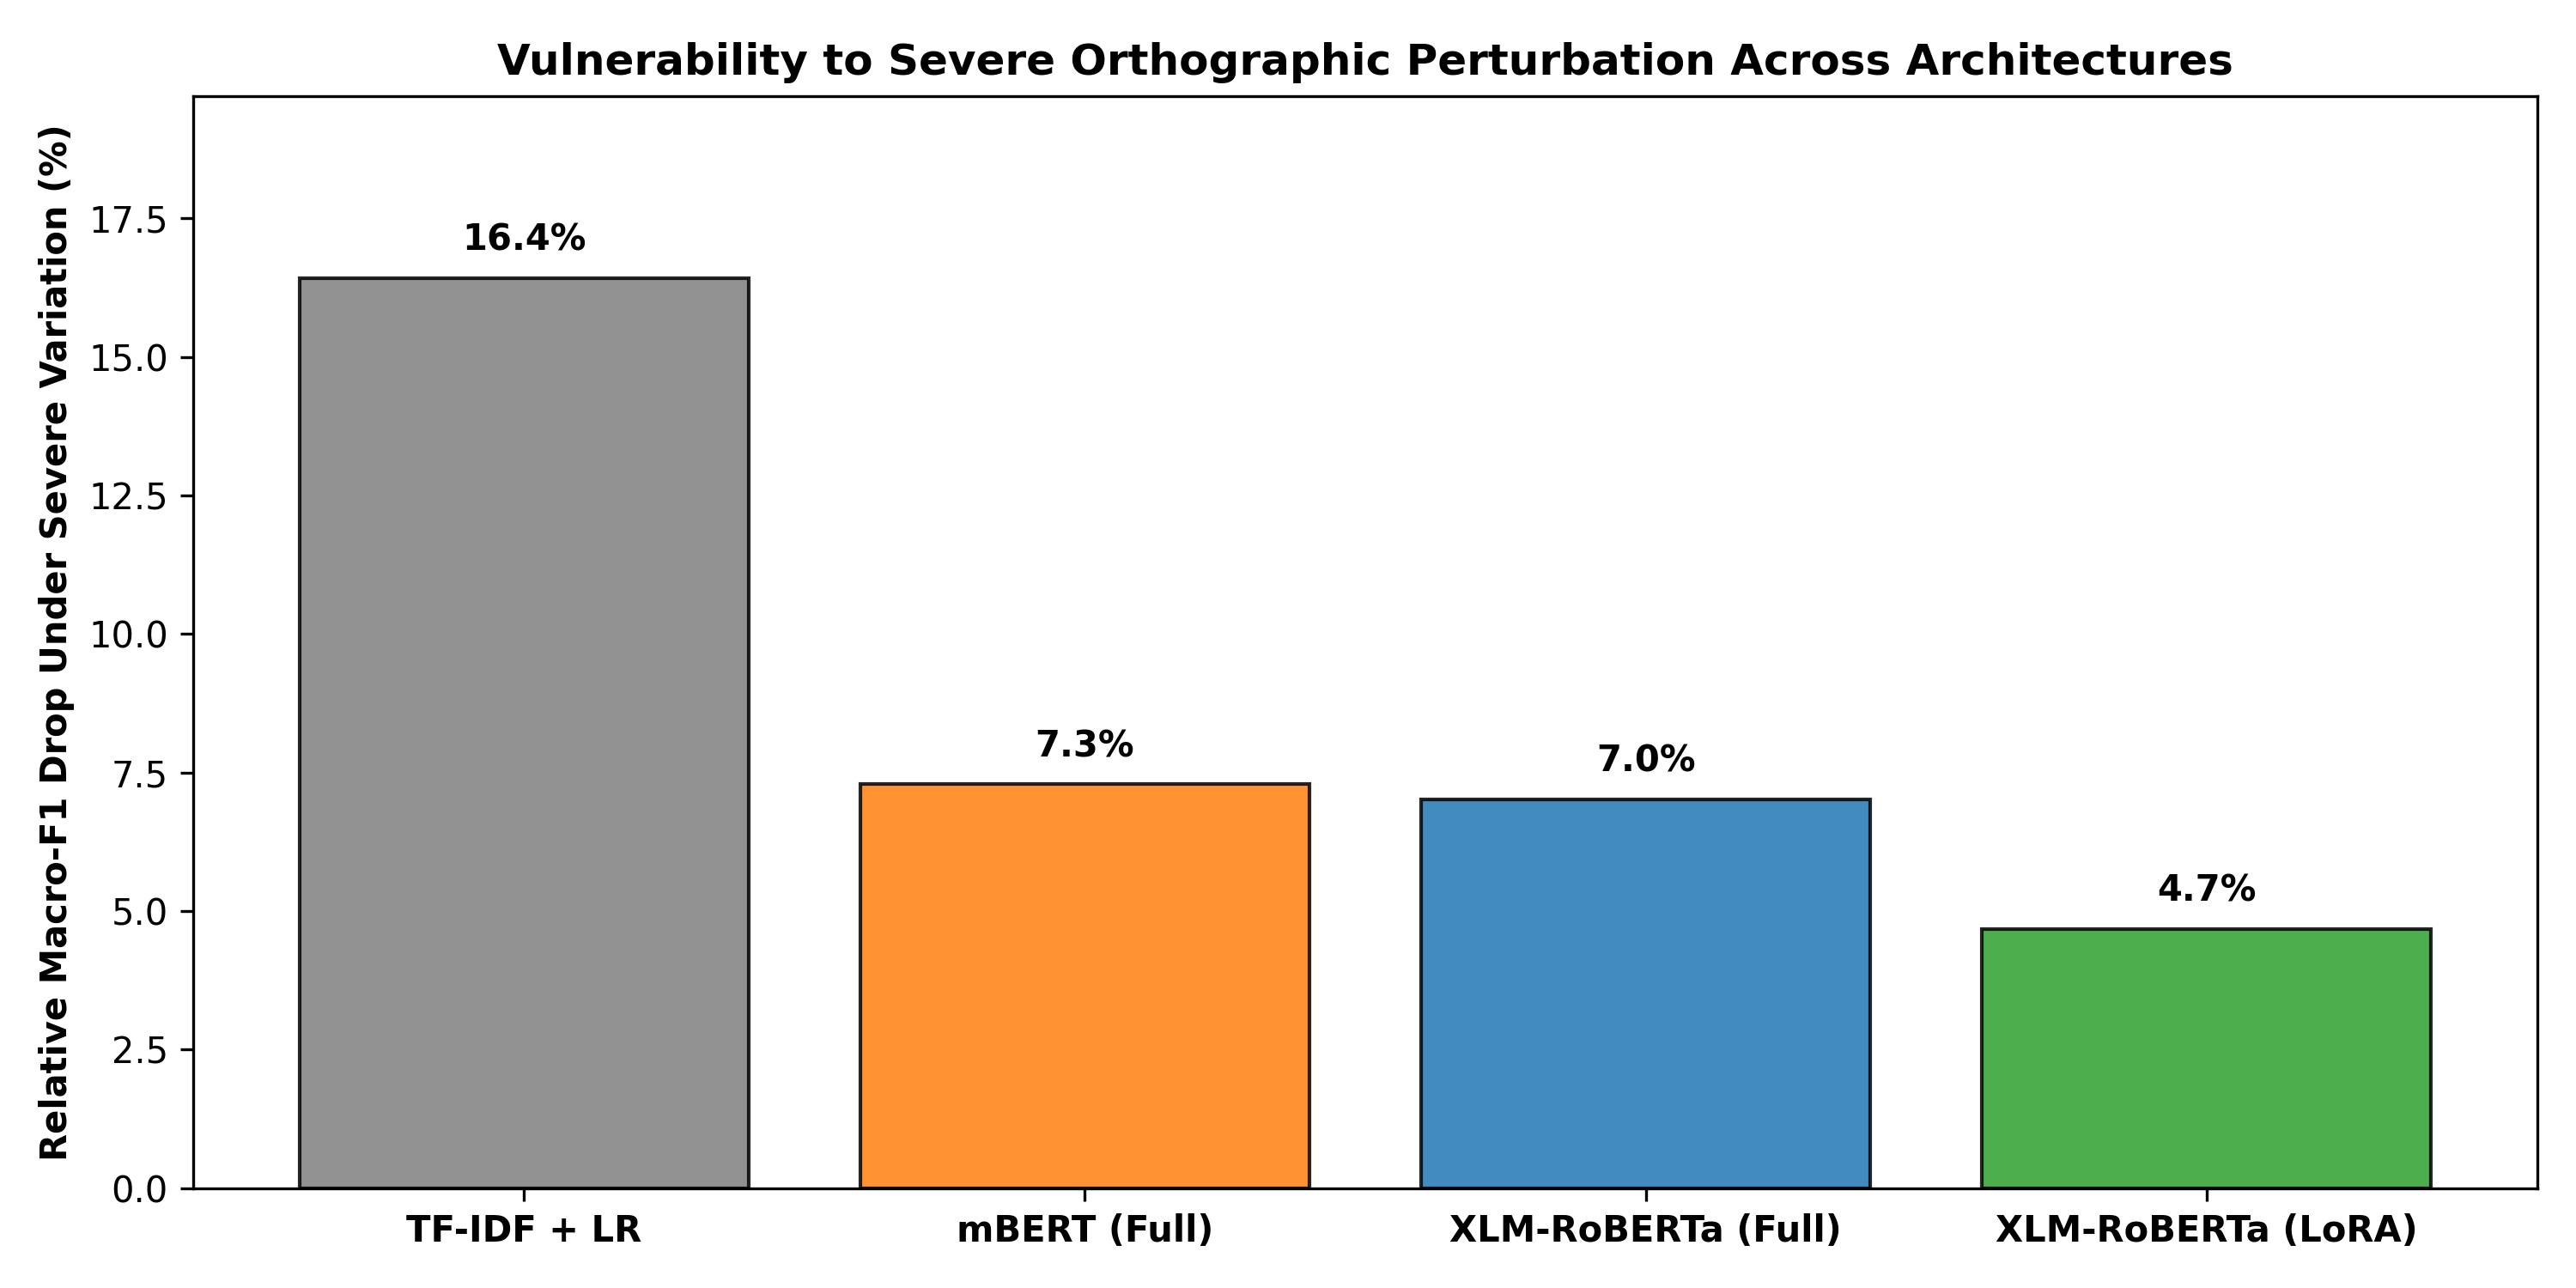

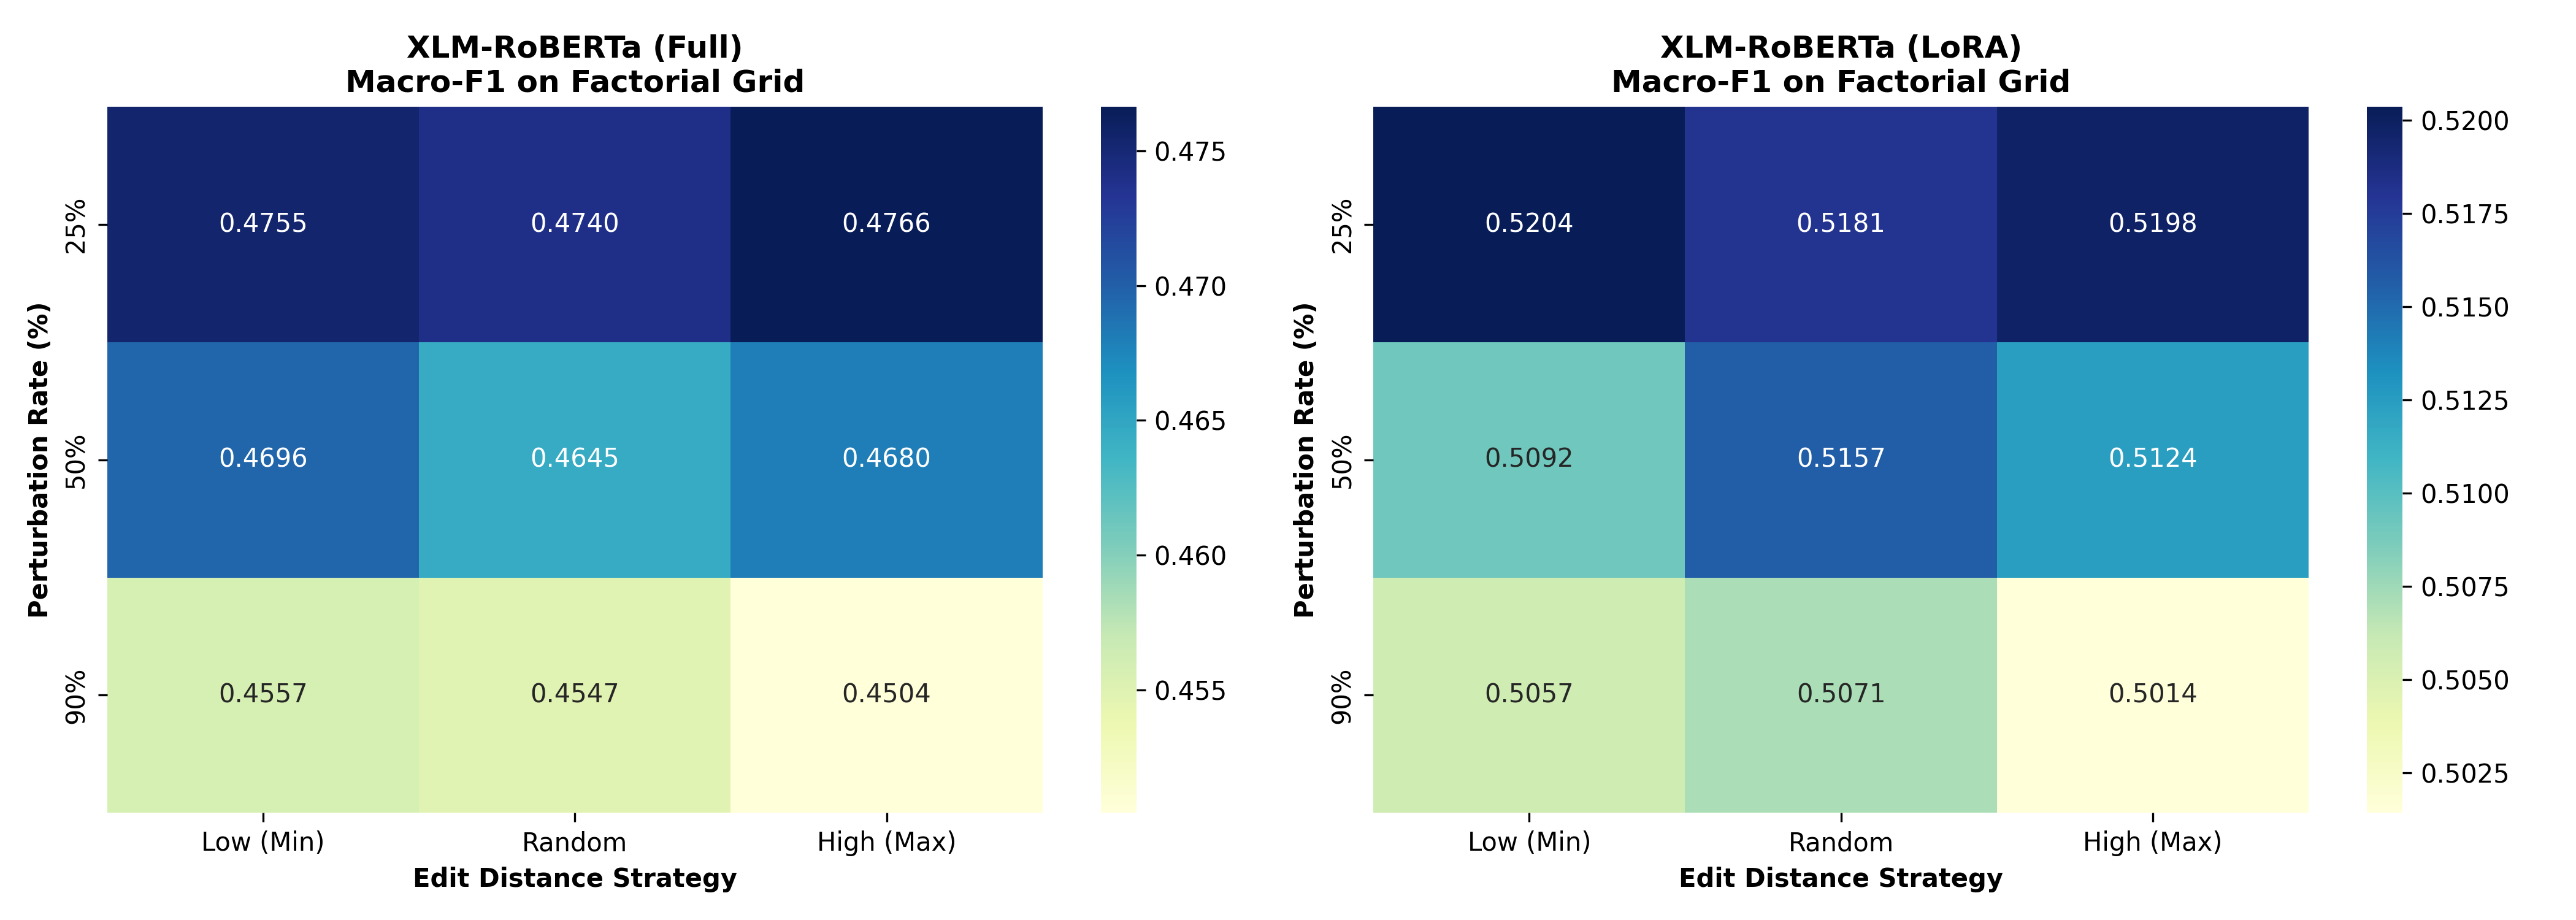

In [3]:
display(Image(filename=os.path.join(PROJECT_ROOT, "results", "figures", "experiment_A_robustness_curves.png")))
display(Image(filename=os.path.join(PROJECT_ROOT, "results", "figures", "experiment_A_relative_drop.png")))
display(Image(filename=os.path.join(PROJECT_ROOT, "results", "figures", "experiment_A_factorial_heatmap.png")))


### 3. Experiment B: Robust Data Augmentation Comparison


,model,condition,accuracy,macro_f1,macro_precision,macro_recall,weighted_f1,delta_macro_f1,rel_drop_macro_f1_pct,delta_accuracy,rel_drop_accuracy_pct,training_regime
0,TF-IDF + LR,clean,0.544473,0.550812,0.544874,0.561026,0.541704,0.000000,0.000000,0.000000,0.000000,Clean-Only
1,XLM-RoBERTa (LoRA),clean,0.522023,0.529388,0.535061,0.534680,0.517364,0.000000,0.000000,0.000000,0.000000,Clean-Only
2,TF-IDF + LR,mild,0.508667,0.513548,0.508688,0.521786,0.506036,0.037264,6.765331,0.035806,6.576200,Clean-Only
3,XLM-RoBERTa (LoRA),mild,0.512646,0.519706,0.529598,0.523359,0.507218,0.009682,1.828835,0.009378,1.796407,Clean-Only
4,TF-IDF + LR,moderate,0.490764,0.492427,0.488273,0.501222,0.486859,0.058385,10.599779,0.053708,9.864301,Clean-Only
5,XLM-RoBERTa (LoRA),moderate,0.507815,0.515693,0.525607,0.519704,0.503095,0.013695,2.586861,0.014209,2.721829,Clean-Only
6,TF-IDF + LR,severe,0.466041,0.460360,0.463064,0.467005,0.459808,0.090452,16.421546,0.078431,14.405010,Clean-Only
7,XLM-RoBERTa (LoRA),severe,0.496448,0.504590,0.514332,0.507216,0.491527,0.024797,4.684141,0.025575,4.899292,Clean-Only
8,TF-IDF (Augmented),clean,0.538221,0.546417,0.539475,0.556266,NaN,NaN,NaN,NaN,NaN,Augmented
9,XLM-R LoRA (Augmented),clean,0.539074,0.550177,0.562471,0.549972,NaN,NaN,NaN,NaN,NaN,Augmented


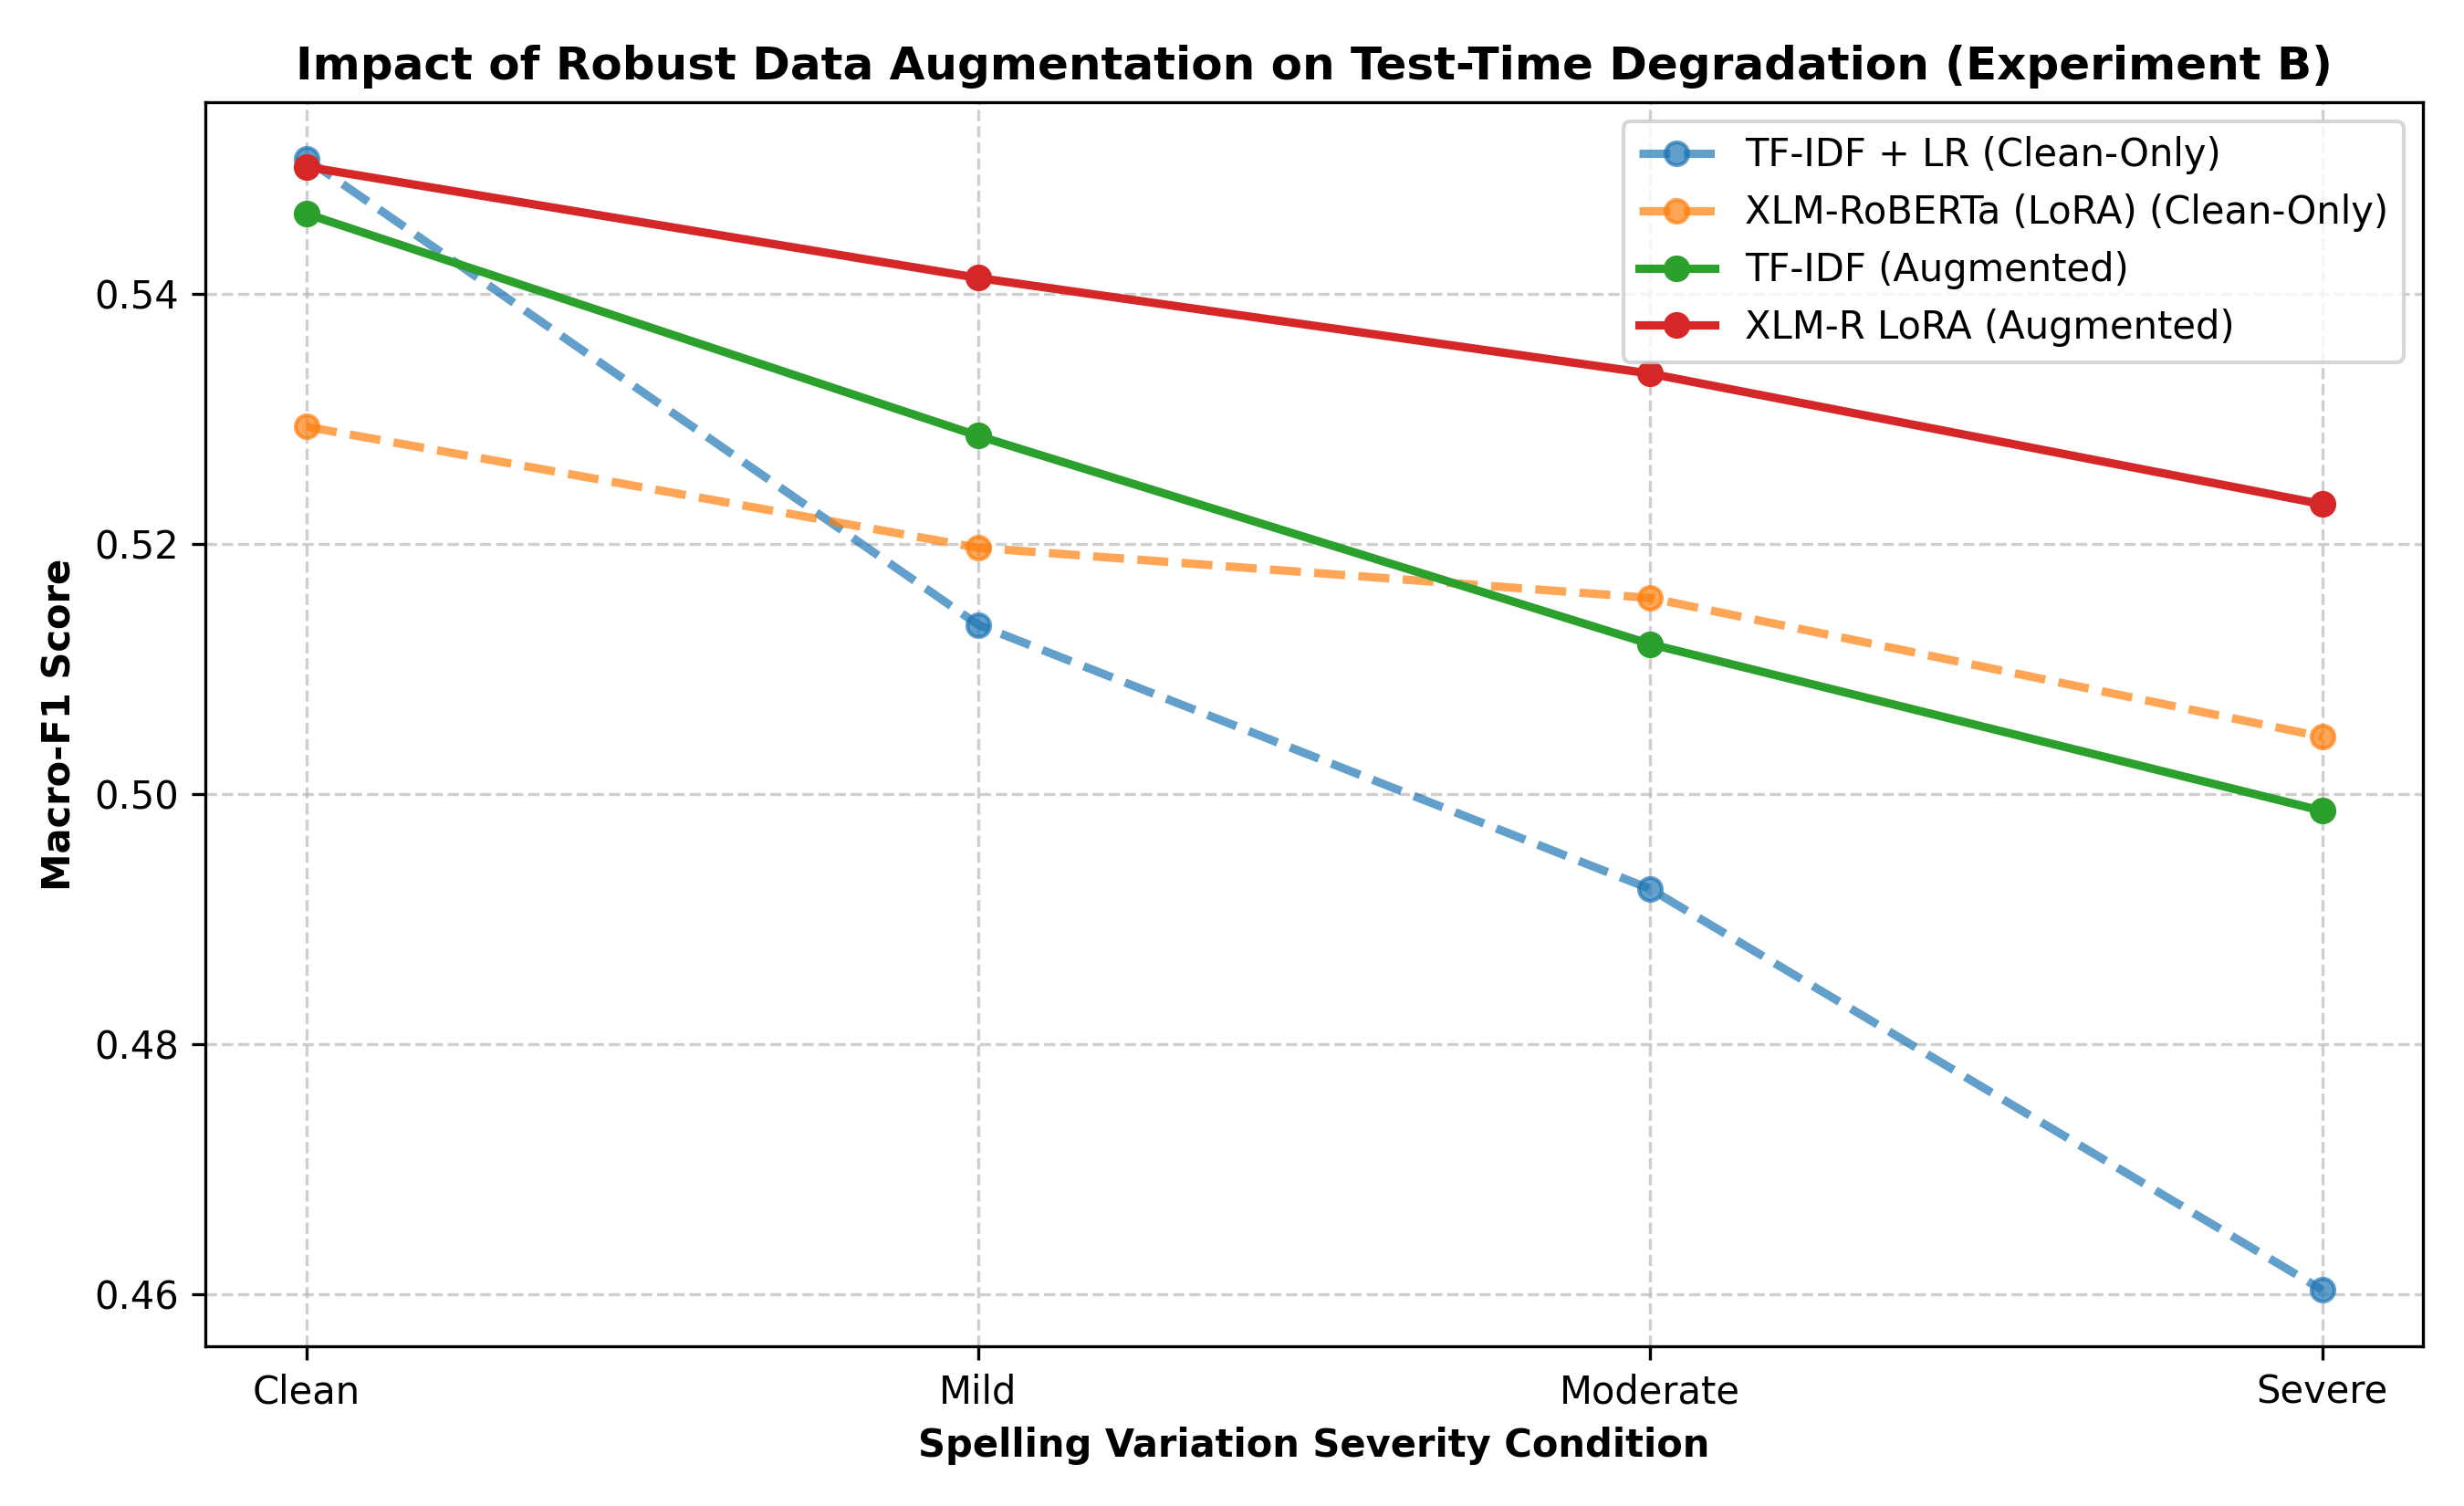

In [4]:
exp_b_path = os.path.join(PROJECT_ROOT, "results", "tables", "experiment_B_augmented_comparison.csv")
exp_b_df = pd.read_csv(exp_b_path)
display(exp_b_df)
display(Image(filename=os.path.join(PROJECT_ROOT, "results", "figures", "experiment_B_augmented_comparison.png")))


### 4. Experiment C: Normalization Recovery Ablation (Conditions A, B, C, D)


,model,normalization_condition,norm_key,accuracy,macro_f1,macro_precision,macro_recall,clean_macro_f1,raw_severe_f1,f1_gain_over_raw,pct_degradation_recovered
0,TF-IDF + LR,Condition A: Raw (No Norm),raw,0.466041,0.460360,0.463064,0.467005,0.550812,0.460360,0.000000,0.000000
1,XLM-RoBERTa (LoRA),Condition A: Raw (No Norm),raw,0.496448,0.504652,0.514400,0.507222,0.529878,0.504652,0.000000,0.000000
2,TF-IDF + LR,Condition B: Generic Preprocessing,generic,0.465757,0.459299,0.460792,0.468114,0.550812,0.460360,-0.001061,0.000000
3,XLM-RoBERTa (LoRA),Condition B: Generic Preprocessing,generic,0.493322,0.500613,0.511593,0.504121,0.529878,0.504652,-0.004039,0.000000
4,TF-IDF + LR,Condition C: Lexicon Normalization,lexicon,0.537369,0.545197,0.539474,0.555531,0.550812,0.460360,0.084837,93.792487
5,XLM-RoBERTa (LoRA),Condition C: Lexicon Normalization,lexicon,0.518329,0.525900,0.531193,0.531063,0.529878,0.504652,0.021248,84.231065
6,TF-IDF + LR,Condition D: Combined (Generic + Lexicon),combined,0.531969,0.537397,0.532375,0.546332,0.550812,0.460360,0.077036,85.168481
7,XLM-RoBERTa (LoRA),Condition D: Combined (Generic + Lexicon),combined,0.516340,0.525223,0.532726,0.529525,0.529878,0.504652,0.020571,81.546219


,density_quartile,mean_perturbation_rate,count,macro_f1_clean,macro_f1_raw_severe,macro_f1_normalized,drop_clean_to_raw,gain_raw_to_norm
0,Q1 (Low Density),0.565895,880,0.530631,0.507632,0.522658,0.022999,0.015026
1,Q2 (Medium-Low),0.779706,880,0.524473,0.497611,0.531927,0.026862,0.034315
2,Q3 (Medium-High),0.854323,879,0.484212,0.475272,0.475439,0.008941,0.000167
3,Q4 (High Density),1.000000,880,0.518639,0.474809,0.505112,0.043830,0.030303


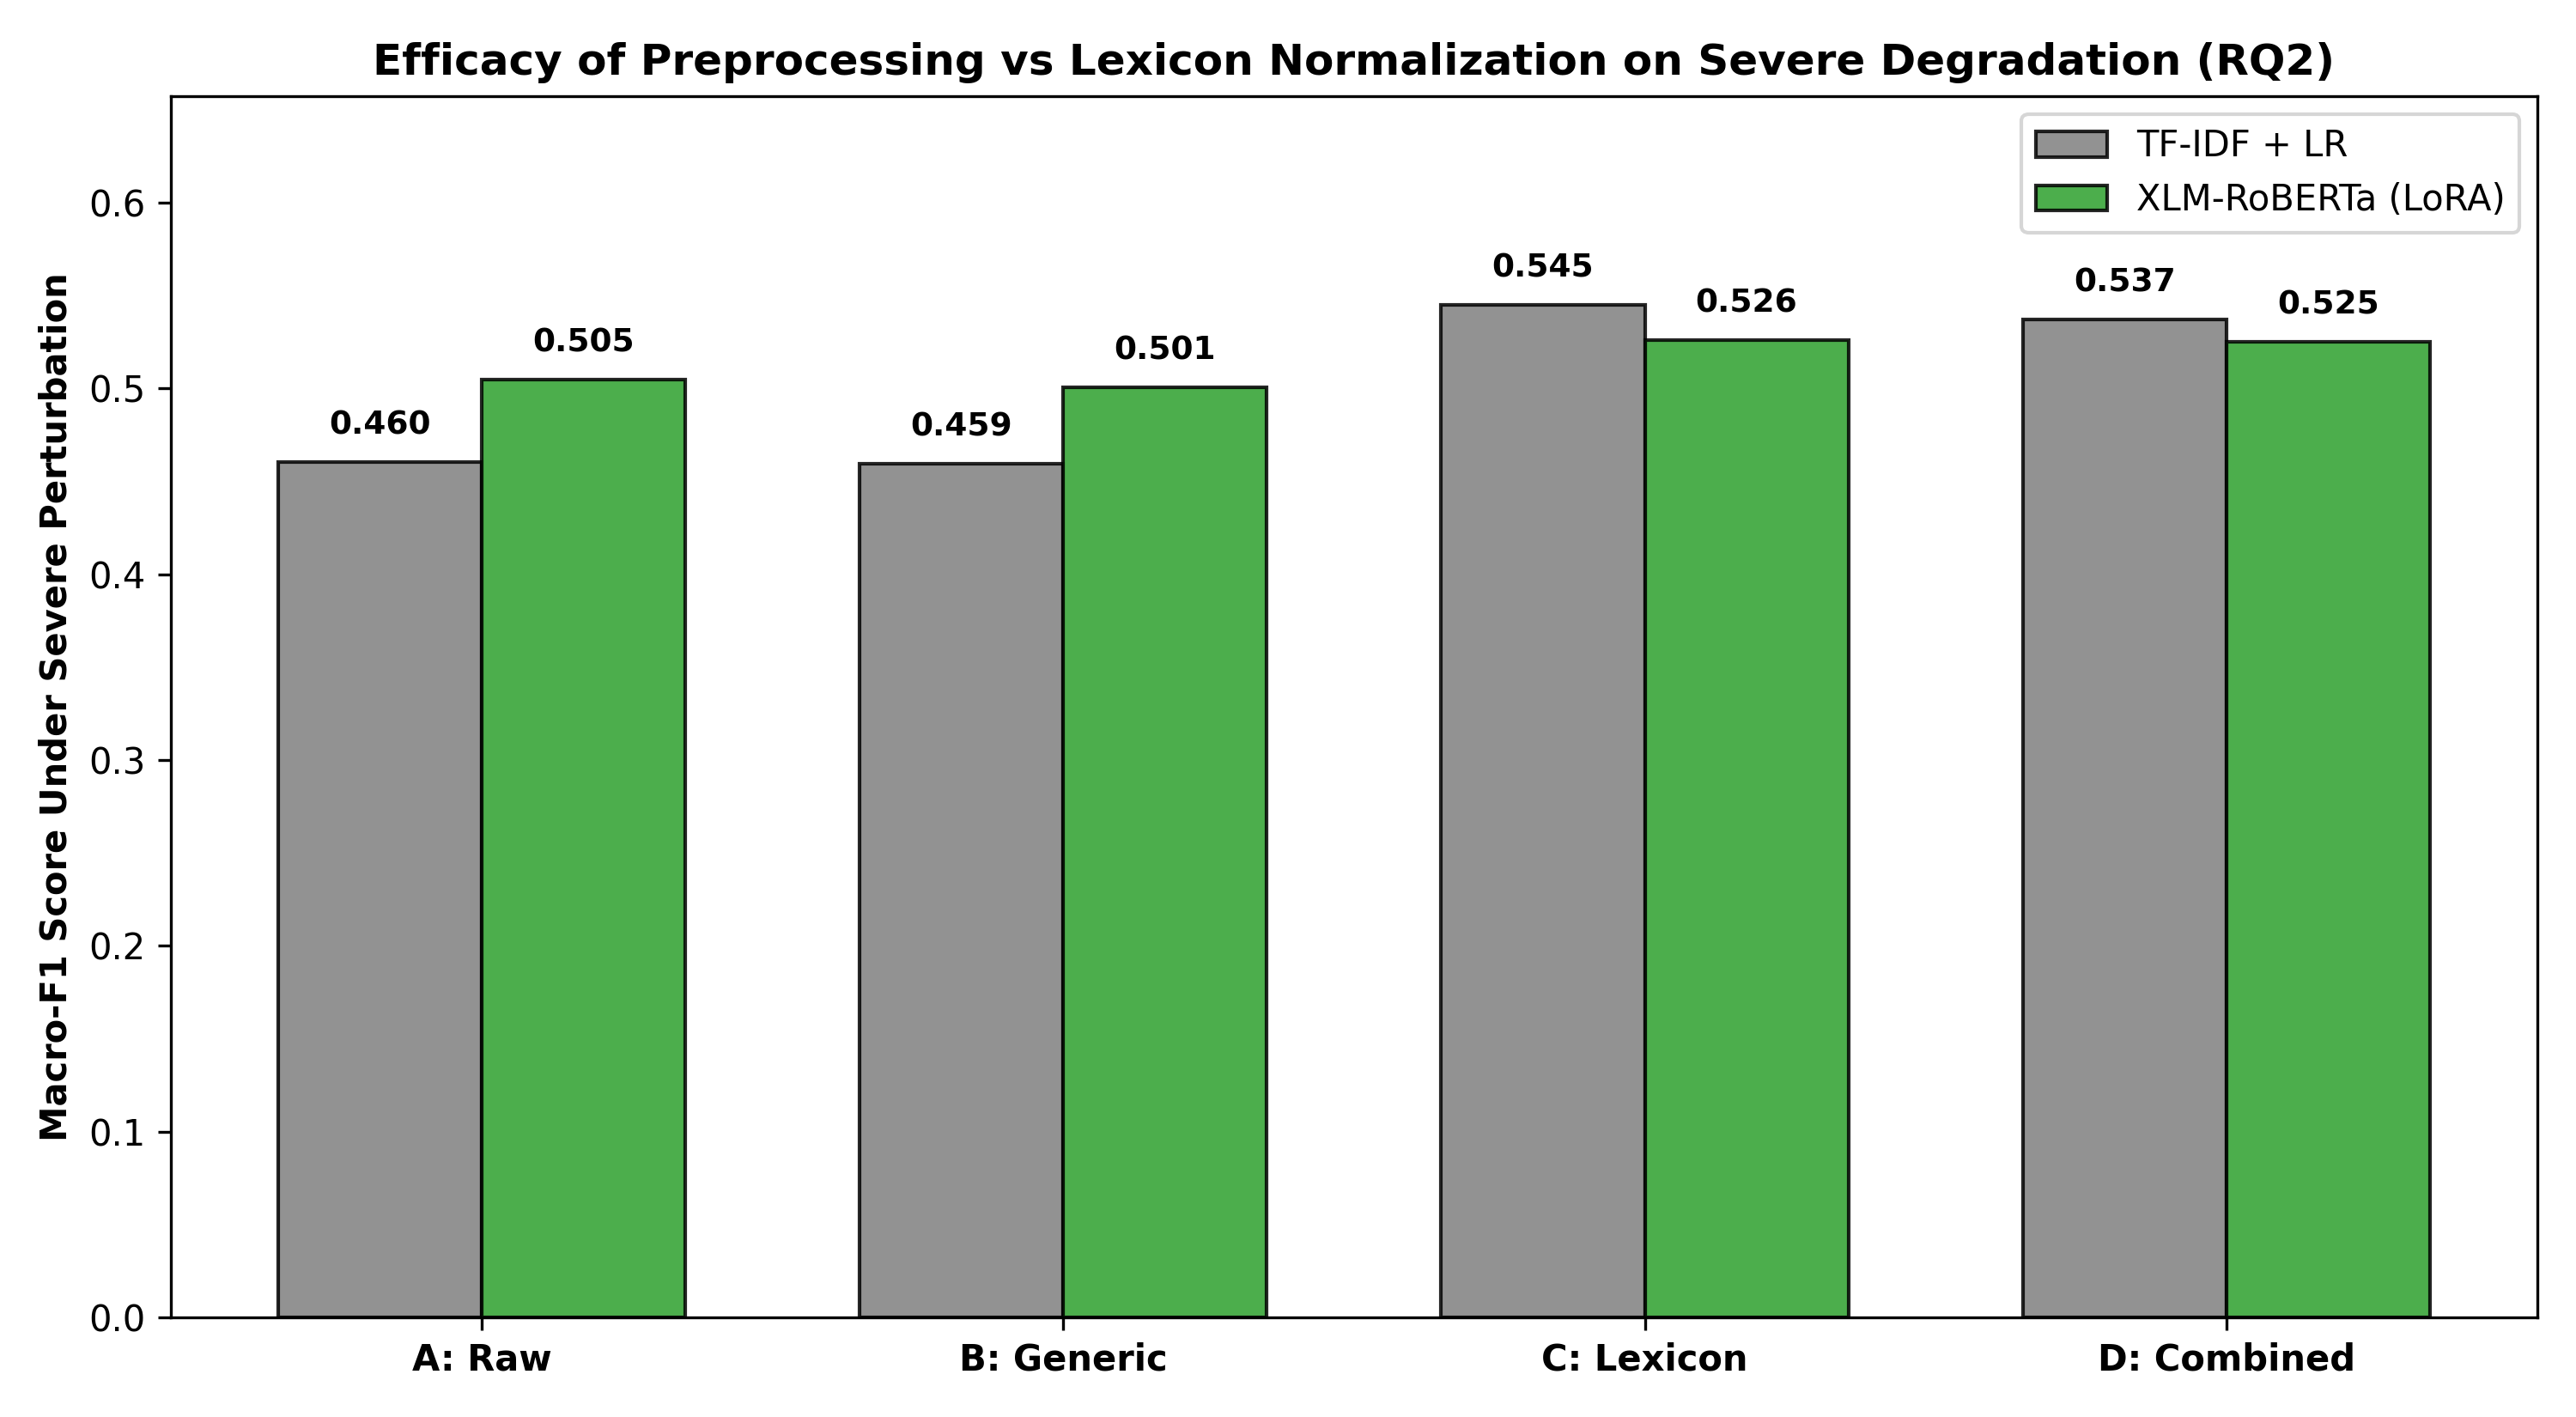

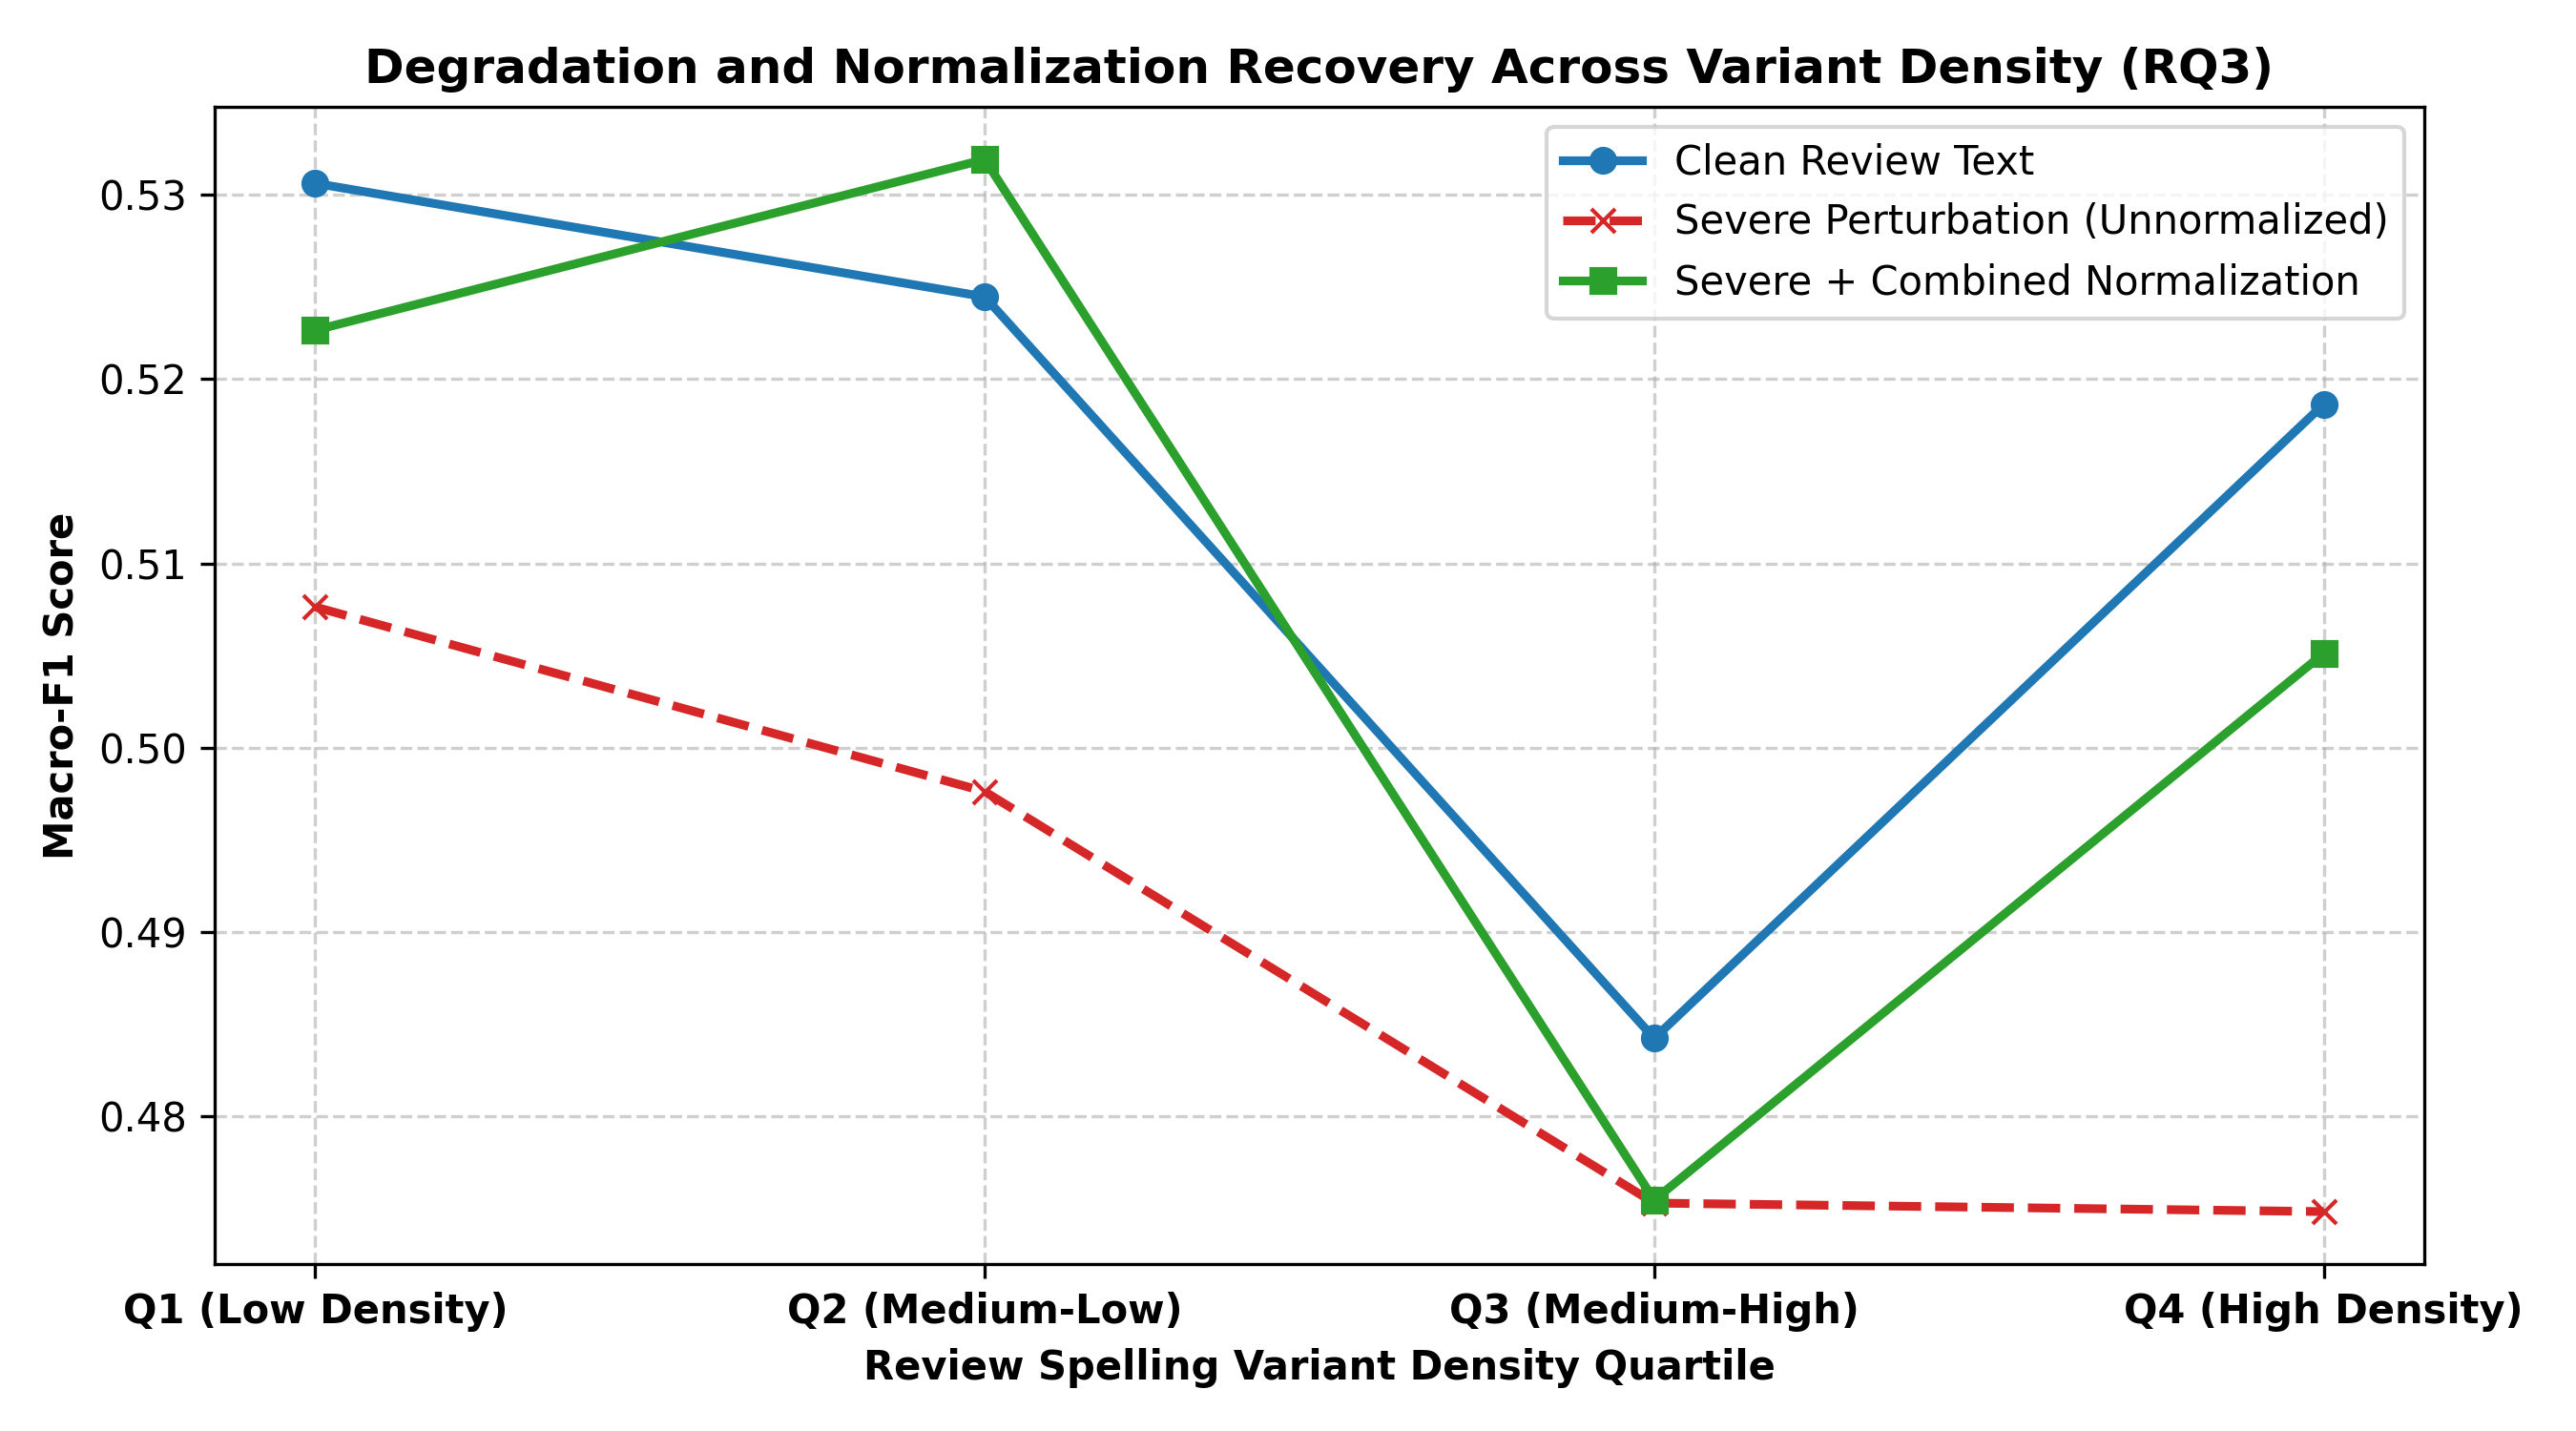

In [5]:
exp_c_path = os.path.join(PROJECT_ROOT, "results", "tables", "experiment_C_normalization_results.csv")
exp_c_df = pd.read_csv(exp_c_path)
display(exp_c_df)

density_path = os.path.join(PROJECT_ROOT, "results", "tables", "experiment_C_density_analysis.csv")
density_df = pd.read_csv(density_path)
display(density_df)

display(Image(filename=os.path.join(PROJECT_ROOT, "results", "figures", "experiment_C_normalization_recovery.png")))
display(Image(filename=os.path.join(PROJECT_ROOT, "results", "figures", "experiment_C_density_vs_recovery.png")))


### 5. Stage 4: External Validation on RUECD Dataset


In [6]:
ruecd_path = os.path.join(PROJECT_ROOT, "results", "tables", "external_validation_ruecd_results.csv")
ruecd_df = pd.read_csv(ruecd_path)
display(ruecd_df)

overlap_path = os.path.join(PROJECT_ROOT, "results", "tables", "ruecd_overlap_report.json")
with open(overlap_path, "r", encoding="utf-8") as f:
    overlap = json.load(f)
print("RUECD Overlap & Transfer Report:")
print(json.dumps(overlap, indent=2))


RUECD Overlap & Transfer Report:
{
  "ruecd_total": 26824,
  "ruecd_sentiment_counts": {
    "positive": 9833,
    "neutral": 8739,
    "negative": 8252
  },
  "overlap_count": 656,
  "overlap_pct": 2.445571130331047
}


,model,dataset,condition,accuracy,macro_f1,macro_precision,macro_recall,n_samples
0,TF-IDF + LR,RUECD (Daraz.pk),clean,0.510333,0.497184,0.498803,0.504520,3000
1,TF-IDF + LR,RUECD (Daraz.pk),mild,0.503000,0.489587,0.490474,0.498342,3000
2,TF-IDF + LR,RUECD (Daraz.pk),moderate,0.495667,0.480594,0.482654,0.489912,3000
3,TF-IDF + LR,RUECD (Daraz.pk),severe,0.476333,0.462448,0.466364,0.469749,3000
4,XLM-RoBERTa (LoRA),RUECD (Daraz.pk),clean,0.508000,0.495934,0.502239,0.500599,3000
5,XLM-RoBERTa (LoRA),RUECD (Daraz.pk),mild,0.502000,0.490696,0.493766,0.495700,3000
6,XLM-RoBERTa (LoRA),RUECD (Daraz.pk),moderate,0.507333,0.496669,0.498669,0.501758,3000
7,XLM-RoBERTa (LoRA),RUECD (Daraz.pk),severe,0.475667,0.467374,0.467112,0.472951,3000
